# Homework 8: Neural Networks and Deep Learning

Questions: [ML Zoomcamp 2026 – Homework 8](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/08-deep-learning/homework.md)

Dataset: [straight/curly hair images](https://github.com/SVizor42/ML_Zoomcamp/releases/download/straight-curly-data/data.zip) (fixed 800/201 train/evaluation split)

The model, transforms, loaders and training loop live in `common.py`; the run reproduces `reference_train.py` exactly.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from common import SEED, HairModel, evaluation_transform, make_loader, seed_everything, train_phase, train_transform_augmented

## Setup

Seed everything before building datasets, loaders, model and optimizer. Two CPU threads match the reference run.

In [2]:
seed_everything()
torch.set_num_threads(2)

evaluation_loader = make_loader("test", evaluation_transform)
baseline_loader = make_loader("train", evaluation_transform, seed=SEED)
len(baseline_loader.dataset), len(evaluation_loader.dataset), baseline_loader.dataset.class_to_idx

(800, 201, {'curly': 0, 'straight': 1})

In [3]:
model = HairModel()
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.002, momentum=0.8)
model

HairModel(
  (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (hidden): Linear(in_features=313632, out_features=64, bias=True)
  (output): Linear(in_features=64, out_features=1, bias=True)
)

## Question 1 — loss

The model outputs a single raw logit, so the loss must apply sigmoid + binary cross-entropy itself.

**Answer: `nn.BCEWithLogitsLoss()`**

## Question 2 — parameter count

In [4]:
{name: p.numel() for name, p in model.named_parameters()}, sum(p.numel() for p in model.parameters())

({'conv.weight': 864,
  'conv.bias': 32,
  'hidden.weight': 20072448,
  'hidden.bias': 64,
  'output.weight': 64,
  'output.bias': 1},
 20073473)

The hidden layer (32·99·99 inputs × 64) dominates.

**Answer: 20073473**

## Baseline training (10 epochs)

In [5]:
baseline = train_phase(model, baseline_loader, evaluation_loader, criterion, optimizer)
with open("history_baseline.json", "w") as f:
    json.dump(baseline, f, indent=2)

epoch  1: train loss=0.6385 acc=0.6450 | eval loss=0.6010 acc=0.6567


epoch  2: train loss=0.5441 acc=0.7175 | eval loss=0.6003 acc=0.6517


epoch  3: train loss=0.4955 acc=0.7550 | eval loss=0.6405 acc=0.6219


epoch  4: train loss=0.4330 acc=0.7913 | eval loss=0.6274 acc=0.6915


epoch  5: train loss=0.4048 acc=0.8087 | eval loss=0.6293 acc=0.6617


epoch  6: train loss=0.3953 acc=0.8075 | eval loss=0.6332 acc=0.7114


epoch  7: train loss=0.3437 acc=0.8363 | eval loss=0.6895 acc=0.6716


epoch  8: train loss=0.2806 acc=0.8850 | eval loss=0.6497 acc=0.7214


epoch  9: train loss=0.2236 acc=0.9100 | eval loss=0.7114 acc=0.7164


epoch 10: train loss=0.1584 acc=0.9387 | eval loss=1.0212 acc=0.6368


## Question 3 — median train accuracy

In [6]:
round(float(np.median(baseline["train_accuracy"])), 2)

0.81

**Answer: 0.81**

## Question 4 — std of train loss

In [7]:
round(float(np.std(baseline["train_loss"], ddof=0)), 3)

0.139

**Answer: 0.139**

## Augmented training (10 more epochs)

Same model and optimizer; only the training transform changes. The augmented loader uses seed `SEED + 1`, as in the reference script.

In [8]:
augmented_loader = make_loader("train", train_transform_augmented, seed=SEED + 1)
augmented = train_phase(model, augmented_loader, evaluation_loader, criterion, optimizer)
with open("history_augmented.json", "w") as f:
    json.dump(augmented, f, indent=2)

epoch  1: train loss=0.6758 acc=0.6050 | eval loss=0.6552 acc=0.6716


epoch  2: train loss=0.6129 acc=0.6475 | eval loss=0.6608 acc=0.6269


epoch  3: train loss=0.5899 acc=0.6800 | eval loss=0.5787 acc=0.7114


epoch  4: train loss=0.5923 acc=0.6750 | eval loss=0.5679 acc=0.7114


epoch  5: train loss=0.5604 acc=0.7137 | eval loss=0.5680 acc=0.7214


epoch  6: train loss=0.5567 acc=0.7087 | eval loss=0.5510 acc=0.7015


epoch  7: train loss=0.5441 acc=0.7025 | eval loss=0.5288 acc=0.7413


epoch  8: train loss=0.5329 acc=0.7212 | eval loss=0.5401 acc=0.7114


epoch  9: train loss=0.5019 acc=0.7612 | eval loss=0.5632 acc=0.7363


epoch 10: train loss=0.5312 acc=0.7262 | eval loss=0.5404 acc=0.7313


## Question 5 — mean evaluation loss

In [9]:
round(float(np.mean(augmented["evaluation_loss"])), 3)

0.575

**Answer: 0.575**

## Question 6 — mean evaluation accuracy, last 5 epochs

In [10]:
round(float(np.mean(augmented["evaluation_accuracy"][-5:])), 2)

0.72

**Answer: 0.72**

## Training curves

The baseline overfits (train accuracy climbs to 0.94 while evaluation loss rises). Augmentation lowers train accuracy but improves evaluation loss and accuracy.

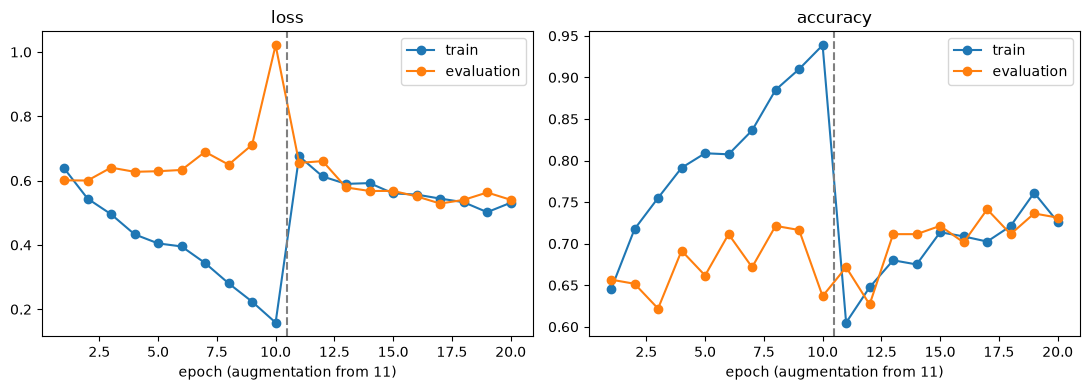

In [11]:
epochs = range(1, 21)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ("loss", "accuracy")):
    for split in ("train", "evaluation"):
        ax.plot(epochs, baseline[f"{split}_{metric}"] + augmented[f"{split}_{metric}"], marker="o", label=split)
    ax.axvline(10.5, color="gray", linestyle="--")
    ax.set(title=metric, xlabel="epoch (augmentation from 11)")
    ax.legend()
plt.tight_layout()